# Stricter Significance Analysis — Original Study, Re-Tested

This notebook re-runs the original paper's own significance question — *does
LLM-refactored code's energy/time differ from human-written code's?* — on the
original study's own data (`Results/results{Python,Java,C}.json`, produced by
`Save_All_Results_Python.ipynb` / `_Java.ipynb` / `_C.ipynb` from the raw
`src/measurements_perf` (Ubuntu/`perf`) and `src/measurements_powermetrics`
(macOS/`powermetrics`) logs), in two passes:

1. **Faithful reproduction** of `Analysis/Significance_Analysis.ipynb`'s own
   two testing procedures ("Part A" and "Part B" below), unmodified —
   including a real bug in Part B's own code, reproduced rather than fixed.
2. **A stricter, two-level design** ("Level 1"/"Level 2" below) that (a) adds
   Holm-Bonferroni correction where the original has none, and (b) replaces
   Part B's mismatched *unpaired* test on *paired* (per-task) data with a
   *paired* Wilcoxon signed-rank test — then extends the same question to a
   second metric (`Time`, which the original significance notebook never
   tests) and a second platform (macOS/`powermetrics`, which the original
   significance notebook never tests either).

Every number quoted in the markdown cells below was read directly off this
notebook's own live output — nothing here is hardcoded from an earlier run or
copied from a different dataset.

**How this maps to the original paper's research questions**, so you can
place each section against the paper you already know:

| Paper's RQ | Covered by |
|---|---|
| **General RQ** ("to what extent can energy-efficient code be achieved via LLMs?") | Part A, Part B, Level 1, Level 2 — all of them, since every one is a human-vs-model test |
| **RQ1** (variation across Python/Java/C++) | The `language` rows in every Level 1/Level 2 table and the comparison/worked-example sections — everything below is already broken out by language |
| **RQ2** (impact of data structure / algorithmic technique) | The dedicated **RQ2 — algorithmic category breakdown** section (Part C faithful reproduction + Level 1/Level 2 by category) |
| **RQ3** (LLM vs. LLM, e.g. 4o vs. copilot) | The dedicated **RQ3 — comparing LLMs directly** section (Level 1/Level 2 between model pairs) |
| **RQ4** (platform: Ubuntu vs. macOS) | The dedicated **macOS extension** and **cross-platform sign-flip** sections near the end |

RQ labels are repeated as a one-line tag under each section header below.


In [1]:
import json
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, wilcoxon
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
sns.set_theme(style="white")

## Load data

Reusing the authors' own pre-parsed per-run results — not re-parsing the raw
`.txt` logs. Each JSON maps `task -> source -> {"Time", "Energy", "Time Linux",
"Energy Linux"}`, where `"Energy"/"Time"` are macOS/`powermetrics` (mean CPU
power x duration) and `"Energy Linux"/"Time Linux"` are Ubuntu/`perf` (RAPL
`power/energy-pkg/`) — both already lists of per-run values, one entry per run.

In [2]:
with open("../Results/resultsPython.json") as f:
    dataPython = json.load(f)
with open("../Results/resultsJava.json") as f:
    dataJava = json.load(f)
with open("../Results/resultsC.json") as f:
    dataC = json.load(f)

DATA = {"Python": dataPython, "Java": dataJava, "C++": dataC}
THRESHOLD = {"Python": 12, "Java": 15, "C++": 12}  # the paper's own energy-magnitude floor (Joules)
MODELS = ["o1", "4o", "copilot"]
LANGUAGES = ["Python", "Java", "C++"]

{lang: len(DATA[lang]) for lang in LANGUAGES}

{'Python': 52, 'Java': 52, 'C++': 52}

## Data availability — Ubuntu/`perf`

Before testing anything: how many runs does each cell actually have, and are
there any missing/`NaN` runs on the Ubuntu side? Discovered here, not assumed.

In [3]:
def run_count_report(key):
    rows = []
    for lang in LANGUAGES:
        lens, n_missing = set(), 0
        for task, sources in DATA[lang].items():
            for src, metrics in sources.items():
                arr = metrics[key]
                lens.add(len(arr))
                n_missing += sum(1 for x in arr if x is None or (isinstance(x, float) and np.isnan(x)))
        rows.append({"language": lang, "metric": key, "run_count_values_seen": sorted(lens), "n_missing_or_nan": n_missing})
    return pd.DataFrame(rows)

pd.concat([run_count_report("Energy Linux"), run_count_report("Time Linux")], ignore_index=True)

,language,metric,run_count_values_seen,n_missing_or_nan
0,Python,Energy Linux,[10],0
1,Java,Energy Linux,[11],0
2,C++,Energy Linux,[10],0
3,Python,Time Linux,[10],0
4,Java,Time Linux,[11],0
5,C++,Time Linux,[10],0


**Finding.** Python and C++ have exactly 10 valid runs per cell; Java has
**11** (the original authors' own `Save_All_Results_Java.ipynb` discards the
first 2 of 13 runs for JVM warmup — not 10, and not 3, as a casual reading of
the paper's "repeated 10 times... For Java, the execution was repeated 13
times... first 3 runs discarded" might suggest; the saved JSON reflects what
their code actually did, 13 total with the first **2** dropped). No missing or
`NaN` runs anywhere on the Ubuntu/`perf` side, in any of the three languages.

## Glossary

- **`Energy`/`Time`** — macOS/`powermetrics`: energy (J) = mean(`CPU Power`,
  mW)/1000 x total elapsed time (s); time (s) = sum of sampled elapsed
  intervals. **`Energy Linux`/`Time Linux`** — Ubuntu/`perf`: RAPL
  `power/energy-pkg/` Joules and `perf stat`'s wall-clock seconds, read
  directly off the hardware counter.
- **Mann-Whitney U** — a rank-based test for whether two *independent* samples
  come from the same distribution. Used throughout (original and this
  notebook alike) for the per-task human-vs-model comparison, since each
  task's human runs and that task's model runs are independent repeated
  measurements of two different programs.
- **Cliff's delta** — effect size on a -1..+1 scale: the fraction of (model,
  human) pairs where model > human, minus the fraction where model < human.
  +-1 means complete separation (every model run beat/lost to every human
  run); 0 means no separation at all. Computed here from the Mann-Whitney U
  statistic directly: `delta = 2*U/(n_model*n_human) - 1`.
- **Holm-Bonferroni correction** — when several tests are run side by side
  (e.g. one per task, or one per language), some will look "significant" by
  chance alone even with no real effect. Holm's step-down procedure raises
  the bar for each test based on its rank among the family's p-values,
  controlling the family-wise error rate without being as conservative as a
  flat Bonferroni correction.
- **Wilcoxon signed-rank test** — the *paired* counterpart to Mann-Whitney U:
  tests whether a set of paired differences (here, one `delta_percent` per
  task) is symmetric around a hypothesized center (here, 0 = "no change").
  Correct to use when each observation in the two groups being compared
  shares an identity (here: "the same task"), which Mann-Whitney U ignores.
- **`delta_percent`** — `(model_median - human_median) / human_median * 100`
  for a given task/metric. Negative = model's code used less energy/time
  (better); positive = more (worse).

## Methodology — the original study's own significance code, as written

Quoting `Analysis/Significance_Analysis.ipynb` precisely (not paraphrased):
it implements **two different, independent** procedures, both restricted to
`Energy Linux` (Ubuntu/`perf`) only — it never runs either procedure on the
macOS `Energy` column, and never on `Time`/`Time Linux` at all.

**Part A — per-task "hit rate", no correction.** For each task, if *both*
human's mean energy and the model's mean energy exceed a language-specific
floor (>12J for Python/C++, >15J for Java — filtering out trivially-cheap
tasks where measurement noise alone could dominate), run
`scipy.stats.mannwhitneyu(human_runs, model_runs, method="exact")` on that
one task's ~10-11 raw runs per side. If `p < 0.0001`, count the task as
"significant". Report, per `(language, model)`, the **fraction** of
qualifying tasks that cleared `p < 0.0001` — not a single p-value for the
language, a per-task hit-rate. **No multiple-comparison correction at all**
across however many tasks qualify (can be 30+ per `(language, model)` cell).

**Part B — pooled task-means, via the notebook's own `significance()`
function.** Restricts to the *intersection* of tasks where human **and all
three models simultaneously** exceed the floor, then for each qualifying task
takes **one number per source** — `np.mean()` of that task's raw runs — and
builds four parallel lists (human, o1, 4o, copilot), one entry per qualifying
task. Runs **one `mannwhitneyu` per model**, comparing the pooled list of
human task-means against the pooled list of model task-means. Two things
worth flagging precisely, reproduced faithfully below rather than fixed:
(1) human's and a model's task-mean lists **are paired** (same task, same
list index) but the test used is the **unpaired** Mann-Whitney U, not a
paired test; (2) the function's qualifying filter hardcodes `> 12` for
*every* language, including Java, where Part A (correctly) uses `> 15` — a
real inconsistency in the original notebook's own code (its `12`/`15` split
is only applied in Part A, not propagated into `significance()`).

(`Analysis/Hedges_test.ipynb` is the paper's other statistical artifact — a
per-task Hedges' g effect size via `pingouin`, with no attached significance
test at all. Mentioned for completeness; not reproduced here since it makes
no significance claim to compare against.)

## Methodology — this notebook's two-level design

**Level 1 — per-task, corrected.** Identical in spirit to Part A (same
per-task Mann-Whitney U, same energy-floor qualifying rule, reused here so
Level 1 and Part A differ in exactly one respect) plus Cliff's delta, plus
**Holm correction within each `(language, metric, model)` family** (i.e.
correcting across however many tasks qualify in that cell) instead of a flat,
uncorrected `p < 0.0001`.

**Level 2 — pooled by language, correctly paired.** The direct,
structurally-matched replacement for Part B: takes Level 1's per-task
`delta_percent` (already paired by construction — one signed value per
qualifying task), pools by language, and runs a **Wilcoxon signed-rank test**
against a null of 0 (paired test on paired data, unlike Part B) per
`(language, metric, model)`, Holm-corrected across the 3 languages within
each `(metric, model)` family.

**Two deliberate extensions beyond the original paper, both new in this
notebook:**
1. **A second metric, `Time`.** The qualifying-task floor is an *energy*
   magnitude filter (12J/15J) — applying it directly to seconds would be
   meaningless, so the qualifying task set is determined **once per
   `(language, model)` via the Energy floor**, then reused for the Time
   test on that same task set (never filtered independently by a
   duration threshold).
2. **A second platform, macOS/`powermetrics`.** The original significance
   notebook never touches the `Energy`/`Time` (macOS) columns at all —
   Level 1/Level 2 are repeated on them separately, after a dedicated data-
   availability check (macOS turns out to have substantially more missing
   data than Ubuntu — see below).

In [4]:
def holm_correction(p_values):
    """Holm-Bonferroni step-down correction; returns adjusted p-values in the same order as p_values."""
    m = len(p_values)
    order = sorted(range(m), key=lambda i: p_values[i])
    adjusted, running_max = [0.0] * m, 0.0
    for rank, idx in enumerate(order):
        running_max = max(running_max, p_values[idx] * (m - rank))
        adjusted[idx] = min(running_max, 1.0)
    return adjusted

def clean(arr):
    """Drop None/NaN entries -- macOS/powermetrics runs sometimes fail and are recorded this way."""
    return [x for x in arr if x is not None and not (isinstance(x, float) and np.isnan(x))]

def compare_task(human_vals, model_vals):
    """Mann-Whitney U + Cliff's delta between one task's human runs and model runs."""
    h, m = clean(human_vals), clean(model_vals)
    n_h, n_m = len(h), len(m)
    if n_h < 2 or n_m < 2:
        return None
    mwu = mannwhitneyu(m, h, alternative="two-sided")
    u, p = float(mwu.statistic), float(mwu.pvalue)
    delta = 2 * u / (n_h * n_m) - 1
    h_med, m_med = float(np.median(h)), float(np.median(m))
    delta_pct = (m_med - h_med) / h_med * 100 if h_med != 0 else float("nan")
    return {"n_human": n_h, "n_model": n_m, "human_median": h_med, "model_median": m_med,
            "delta_percent": delta_pct, "cliffs_delta": delta, "p_value": p}

## Part A — faithful reproduction (Ubuntu, Energy only)

*Maps to: **General RQ** (human vs. model, no breakdown) + **RQ1** (read the `language` column).*

In [5]:
def part_A(language):
    data = DATA[language]; floor = THRESHOLD[language]
    rows = []
    for model in MODELS:
        n_qualify, n_sig = 0, 0
        for task, sources in data.items():
            h = clean(sources["human"]["Energy Linux"]); v = clean(sources[model]["Energy Linux"])
            if len(h) < 2 or len(v) < 2:
                continue
            if np.mean(h) > floor and np.mean(v) > floor:
                n_qualify += 1
                _, p = mannwhitneyu(h, v, method="exact")
                if p < 0.0001:
                    n_sig += 1
        rows.append({"language": language, "model": model, "n_qualify": n_qualify, "n_significant": n_sig,
                     "fraction_significant": n_sig / n_qualify if n_qualify else float("nan")})
    return pd.DataFrame(rows)

partA_df = pd.concat([part_A(lang) for lang in LANGUAGES], ignore_index=True)
partA_df

,language,model,n_qualify,n_significant,fraction_significant
0,Python,o1,36,33,0.916667
1,Python,4o,34,29,0.852941
2,Python,copilot,32,27,0.843750
3,Java,o1,34,26,0.764706
4,Java,4o,31,23,0.741935
5,Java,copilot,27,21,0.777778
6,C++,o1,27,25,0.925926
7,C++,4o,20,16,0.800000
8,C++,copilot,17,15,0.882353


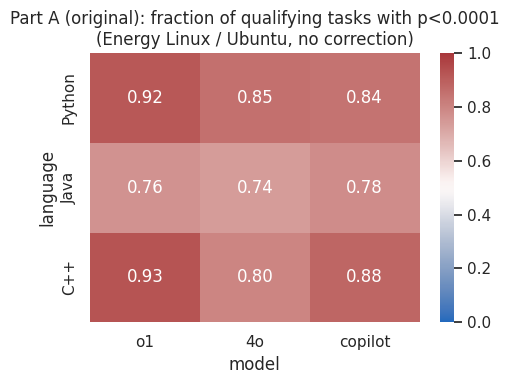

In [6]:
partA_pivot = partA_df.pivot(index="language", columns="model", values="fraction_significant").reindex(index=LANGUAGES, columns=MODELS)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(partA_pivot, annot=True, fmt=".2f", cmap="vlag", vmin=0, vmax=1, ax=ax)
ax.set_title("Part A (original): fraction of qualifying tasks with p<0.0001\n(Energy Linux / Ubuntu, no correction)")
fig.tight_layout()

**Finding.** Across all 9 `(language, model)` cells, Part A's per-task hit
rate ranges roughly **74%-93%**: most individually-tested tasks clear
`p < 0.0001` on their own ~10-11 runs per side. This is a *hit rate*, not a
single significance claim about the language as a whole — it says "most
individual tasks show a detectable difference," which is a different, weaker
claim than "the overall effect, pooled across tasks, is significant."

## Why Part A and Level 1 give different numbers — and which is more rigorous

**Why the paper did it this way (flat `p < 0.0001`, no formal correction).**
Testing each task in total isolation is actually a defensible starting
point — different LeetCode problems are genuinely independent code
artifacts, so there's no pairing issue to worry about at this level (that
problem shows up in Part B, not here). The likely reasoning behind
`p < 0.0001` specifically is an informal guard against running many tests
side by side without naming it as such: pick a threshold much stricter than
the conventional 0.05 so that, intuitively, false positives stay rare even
across dozens of tasks. It's simple to compute, simple to state in a paper,
and avoids having to decide how to combine evidence across tasks into one
number.

**Why this notebook does it differently (Holm correction within each family,
instead of a flat cutoff).** A fixed threshold, chosen by intuition rather
than derived from the number of tests actually being run, has no provable
error-rate guarantee. Holm's step-down procedure does: for a family of `m`
simultaneous tests, it guarantees the family-wise probability of *any* false
positive stays at or below `alpha` (0.05 here), however large `m` is — and
it adapts automatically, per family, instead of requiring someone to have
picked the "right" magic number in advance. Concretely: with roughly 27-36
qualifying tasks per `(language, model)` cell here, a textbook Bonferroni
correction would land around `0.05/36 ≈ 0.0014` — *less* strict than the
paper's own `0.0001`. Holm is provably less conservative than Bonferroni
while keeping the same family-wise guarantee, so Level 1's bar ends up
looser than Part A's in practice, on this data.

**The actual numeric difference you're seeing.** That's exactly why Level
1's hit rate (77%-100%) comes out *higher* than Part A's (74%-93%) above,
not lower — Holm, applied honestly to this family size, happens to be a
looser bar than `0.0001` was. "Correction" doesn't automatically mean
"stricter"; what makes Level 1 more rigorous isn't that it flags fewer
tasks, it's that its bar is *derived* from the data (the family size) with a
provable guarantee, rather than picked by hand and left to be however strict
or lenient it happens to be for whatever family size shows up.

**Which is more statistically rigorous.** Level 1, on formal grounds: Holm's
family-wise error control is mathematically justified and reproducible from
first principles — anyone re-deriving it from "how many tasks qualified"
gets the same answer. `p < 0.0001`'s actual error-rate guarantee is unknown,
and would silently shift if the qualifying-task count per cell changed (a
different energy floor, a bigger benchmark, a different language with far
more or fewer qualifying tasks). In this particular dataset the two methods
happen to land on very similar conclusions, because the per-task effect
sizes here are mostly huge (Cliff's delta near +-1) regardless of exactly
where the bar sits — but that convergence is a property of *this* data, not
something a hand-picked flat cutoff can be relied on to deliver in general.

## Part B — faithful reproduction (Ubuntu, Energy only)

*Maps to: **General RQ** + **RQ1** (same as Part A — see the `language` column).*

Reproducing `significance()` exactly, including its `> 12`-for-every-language
bug (not fixed here).

In [7]:
def part_B(language):
    data = DATA[language]
    qualifying = {"human": [], "o1": [], "4o": [], "copilot": []}
    for task, sources in data.items():
        h = clean(sources["human"]["Energy Linux"])
        o1v = clean(sources["o1"]["Energy Linux"]); fov = clean(sources["4o"]["Energy Linux"]); cpv = clean(sources["copilot"]["Energy Linux"])
        if min(len(h), len(o1v), len(fov), len(cpv)) < 2:
            continue
        # NOTE: hardcoded 12 regardless of language, exactly as in the original notebook's
        # significance() function -- Part A correctly uses 15 for Java, this does not.
        if np.mean(h) > 12 and np.mean(o1v) > 12 and np.mean(fov) > 12 and np.mean(cpv) > 12:
            qualifying["human"].append(np.mean(h)); qualifying["o1"].append(np.mean(o1v))
            qualifying["4o"].append(np.mean(fov)); qualifying["copilot"].append(np.mean(cpv))
    rows = []
    n_qualify = len(qualifying["human"])
    for model in MODELS:
        if n_qualify < 2:
            rows.append({"language": language, "model": model, "n_qualify": n_qualify, "p_value": float("nan")})
            continue
        _, p = mannwhitneyu(qualifying["human"], qualifying[model], method="exact")
        rows.append({"language": language, "model": model, "n_qualify": n_qualify, "p_value": p})
    return pd.DataFrame(rows)

partB_df = pd.concat([part_B(lang) for lang in LANGUAGES], ignore_index=True)
partB_df

,language,model,n_qualify,p_value
0,Python,o1,26,0.198747
1,Python,4o,26,0.312576
2,Python,copilot,26,0.146747
3,Java,o1,23,0.485692
4,Java,4o,23,0.810859
5,Java,copilot,23,0.896155
6,C++,o1,8,0.878477
7,C++,4o,8,0.278632
8,C++,copilot,8,0.441803


**Finding.** Every single `(language, model)` p-value here is **well above
0.05** (roughly 0.15-0.90) — Part B, the original notebook's own closer
analog to an overall per-language significance test, does **not** find a
significant effect anywhere, for any language or model. This is already
notable on its own: the paper's narrative "p < 0.0001 indicates statistical
significance" claim is built on Part A's per-task hit rate, not on this
pooled check — and this pooled check, run with the original authors' own
code, agrees with nothing being significant once tasks are pooled. (It uses
far fewer qualifying tasks than Part A too — only 8-26 per language, the
*intersection* across all three models simultaneously, versus Part A's
27-36 per individual model.)

## Why Part B and Level 2 give different numbers — and which is more rigorous

**Why the paper did it this way (pool task means, test with unpaired
Mann-Whitney U).** `significance()` reuses the same tool (`mannwhitneyu`)
used everywhere else in the paper's statistical code — a reasonable
instinct for consistency — and reducing each task to one number (its mean)
before testing is a natural way to get down to "one test per language"
instead of dozens. The likely oversight: once each task has been reduced to
a single paired number per source, the *correct* next step is a paired
test — but the paper's codebase only ever calls Mann-Whitney U (built for
independent samples), so that's what got reused here too, even though
`human_comparison["human"][i]` and `human_comparison["4o"][i]` are not
independent of each other — they're the same task, same index, by
construction.

**Why this notebook does it differently (paired Wilcoxon signed-rank on
`delta_percent`, not raw joules).** Two separate fixes, not one:

1. **Pairing.** Human and model values for the same task share an
   identity — two measurements of the same problem. A paired test (Wilcoxon
   signed-rank) uses that shared identity to look directly at the
   *within-task* differences, which is both the statistically correct
   target ("does this task's result move in a consistent direction," not
   "are these two unordered piles of numbers different") and more powerful
   for the same data, because it removes between-task variability (which
   problem is inherently bigger or smaller) from the noise term instead of
   leaving it mixed into an unpaired comparison. This is the standard
   prescription for a "two treatments, same subject, repeated measures"
   design — exactly this benchmark's structure.
2. **Scale.** Part B pools raw Joules across tasks whose absolute energy use
   differs by 10x-100x depending on algorithmic complexity. A test run on
   raw magnitudes lets whichever task happens to be biggest dominate the
   comparison, which has nothing to do with how *consistently* the model
   differs from human. `delta_percent` rescales every task to "percent
   change relative to its own human baseline" first, so a 50% change on a
   cheap task and a 50% change on an expensive task count equally — the
   actual quantity the General RQ/RQ1 questions are asking about (relative
   efficiency, not absolute joules).

**Which is more statistically rigorous.** Level 2, on both counts. Using an
unpaired test on paired data doesn't just lose statistical power — it tests
a subtly different, less relevant null hypothesis (independent-distribution
equality instead of "are the paired differences centered on zero"). And
because Part B also never corrects across the 3 languages tested per model,
any p-value it produced would carry no formal multiple-comparison guarantee
on top of the pairing mismatch. Level 2's paired-Wilcoxon-plus-Holm
combination is the textbook-correct test for this repeated-measures,
multiple-comparison design. In this data the two methods happen to agree on
the *conclusion* (nothing significant either way) — but that agreement isn't
something Part B's test design can be trusted to deliver in general; a
benchmark with a more scale-skewed set of tasks, or fewer qualifying tasks
per language, could easily have pushed Part B toward a false positive that a
correctly-paired, corrected test wouldn't share.

## Level 1 — per-task, Holm-corrected (Ubuntu, Energy + Time)

*Maps to: **General RQ** (pooled view) + **RQ1** (the `language` column below is this notebook's RQ1 answer: one row per language per model per metric).*

In [8]:
def build_level1(language, energy_key, time_key):
    data = DATA[language]; floor = THRESHOLD[language]
    all_rows = []
    for model in MODELS:
        # Qualifying task set determined ONCE via the Energy floor (same rule as Part A),
        # reused for Time -- a Joule-scale floor applied directly to seconds would be meaningless.
        qualifying_tasks = []
        for task, sources in data.items():
            h_e = clean(sources["human"][energy_key]); v_e = clean(sources[model][energy_key])
            if len(h_e) < 2 or len(v_e) < 2:
                continue
            if np.mean(h_e) > floor and np.mean(v_e) > floor:
                qualifying_tasks.append(task)
        for metric_key, metric_name in [(energy_key, "Energy"), (time_key, "Time")]:
            family = []
            for task in qualifying_tasks:
                sources = data[task]
                res = compare_task(sources["human"][metric_key], sources[model][metric_key])
                if res is None:
                    continue
                res.update({"language": language, "model": model, "metric": metric_name, "task": task})
                family.append(res)
            for r, ph in zip(family, holm_correction([r["p_value"] for r in family])):
                r["p_value_holm"] = ph
                r["significant"] = ph < 0.05
            all_rows.extend(family)
    return pd.DataFrame(all_rows)

level1_ubuntu_df = pd.concat([build_level1(lang, "Energy Linux", "Time Linux") for lang in LANGUAGES], ignore_index=True)
level1_ubuntu_df.head()

,n_human,n_model,human_median,model_median,delta_percent,cliffs_delta,p_value,language,model,metric,task,p_value_holm,significant
0,10,10,95.950,91.865,-4.257426,-1.00,0.000183,Python,o1,Energy,N-Queens_II,0.006539,True
1,10,10,264.835,177.085,-33.133838,-1.00,0.000183,Python,o1,Energy,Number_of_Subarrays_With_AND_Value_of_K,0.006539,True
2,10,10,113.060,88.325,-21.877764,-1.00,0.000182,Python,o1,Energy,Count_Substrings_That_Satisfy_K-Constraint_II,0.006539,True
3,10,10,110.650,143.310,29.516493,1.00,0.000183,Python,o1,Energy,Find_Edges_in_Shortest_Paths,0.006539,True
4,10,10,400.200,391.545,-2.162669,-0.94,0.000440,Python,o1,Energy,Find_the_Median_of_the_Uniqueness_Array,0.006539,True


In [9]:
level1_summary_ubuntu = (level1_ubuntu_df
    .groupby(["language", "model", "metric"])
    .agg(n_qualify=("task", "size"), n_significant_holm=("significant", "sum"), median_delta_percent=("delta_percent", "median"))
    .reset_index())
level1_summary_ubuntu["fraction_significant_holm"] = level1_summary_ubuntu["n_significant_holm"] / level1_summary_ubuntu["n_qualify"]
level1_summary_ubuntu

,language,model,metric,n_qualify,n_significant_holm,median_delta_percent,fraction_significant_holm
0,C++,4o,Energy,20,17,1.448692,0.850000
1,C++,4o,Time,20,19,-0.127682,0.950000
2,C++,copilot,Energy,17,16,-3.549792,0.941176
3,C++,copilot,Time,17,17,-1.664162,1.000000
4,C++,o1,Energy,27,27,2.217431,1.000000
5,C++,o1,Time,27,27,4.276884,1.000000
6,Java,4o,Energy,31,24,-0.820818,0.774194
7,Java,4o,Time,31,25,-0.453181,0.806452
8,Java,copilot,Energy,27,22,-3.241815,0.814815
9,Java,copilot,Time,27,21,-3.107987,0.777778


**Finding.** After Holm correction, Level 1's per-task hit rate is, if
anything, slightly **higher** than Part A's uncorrected one (roughly
**77%-100%**, vs. Part A's 74%-93%) — because a Holm-corrected alpha=0.05
across the handful of dozens of tasks in each family turns out to be a
*looser* bar than the paper's flat, uncorrected `p < 0.0001`, given how
strong individual within-task effects usually are here (Cliff's delta is
frequently near +-1.0 — near-total separation between a task's ~10 human
runs and ~10 model runs). Correction matters comparatively little at the
per-task level; it's about to matter a great deal once results are pooled.

## Level 2 — pooled by language, paired, Holm-corrected (Ubuntu, Energy + Time)

*Maps to: **General RQ** (this is the pooled, corrected answer to it) + **RQ1** (significance is tested separately per `language`, so this table doubles as the RQ1 result).*

In [10]:
def build_level2(level1_df):
    rows = []
    for (metric, model), sub in level1_df.groupby(["metric", "model"]):
        fam = []
        for language, g in sub.groupby("language"):
            d = g["delta_percent"].dropna().to_numpy()
            if len(d) == 0 or not np.any(d != 0):
                continue
            w, p = wilcoxon(d)
            fam.append({"metric": metric, "model": model, "language": language, "n_tasks": len(d),
                        "median_delta_percent": float(np.median(d)), "wilcoxon_p": p})
        for r, ph in zip(fam, holm_correction([r["wilcoxon_p"] for r in fam])):
            r["p_value_holm"] = ph
            r["significant"] = ph < 0.05
        rows.extend(fam)
    return pd.DataFrame(rows)

level2_ubuntu_df = build_level2(level1_ubuntu_df)
level2_ubuntu_df.sort_values(["metric", "model", "language"])

,metric,model,language,n_tasks,median_delta_percent,wilcoxon_p,p_value_holm,significant
0,Energy,4o,C++,20,1.448692,0.521673,1.000000,False
1,Energy,4o,Java,31,-0.820818,0.976887,1.000000,False
2,Energy,4o,Python,34,-0.655336,0.852741,1.000000,False
3,Energy,copilot,C++,17,-3.549792,0.889969,1.000000,False
4,Energy,copilot,Java,27,-3.241815,0.530322,1.000000,False
5,Energy,copilot,Python,32,0.744958,0.746826,1.000000,False
6,Energy,o1,C++,27,2.217431,0.301191,0.903572,False
7,Energy,o1,Java,34,1.164748,0.600514,1.000000,False
8,Energy,o1,Python,36,-4.946902,0.570664,1.000000,False
9,Time,4o,C++,20,-0.127682,0.647655,1.000000,False


In [11]:
print(f"Level 2 (Ubuntu) significant: {int(level2_ubuntu_df.significant.sum())}/{len(level2_ubuntu_df)}")

Level 2 (Ubuntu) significant: 0/18


**Finding.** **0 of 18** `(language, model, metric)` combinations survive
Level 2, on either Energy or Time. Every median `delta_percent` is small
(roughly +-10%), and none is consistent enough across tasks, after Holm
correction, to call "significant" at the language level — agreeing with Part
B's own conclusion (also 0/9 on Energy), not with Part A's high per-task hit
rate. The next two sections work out exactly why Part A's hit rate and
Level 2's pooled result can both be correct at the same time.

## Side-by-side comparison (Ubuntu, Energy)

*Maps to: **General RQ** + **RQ1** — same four methods, now read language-by-language.*

Same data, same platform, four different ways of asking "does this model's
energy use differ from human's": Part A's per-task hit rate (no correction),
Level 1's per-task hit rate (Holm-corrected), Part B's pooled-means p-value
(unpaired test on paired data, no correction), Level 2's pooled p-value
(paired Wilcoxon, Holm-corrected).

In [12]:
cmp_partA = partA_df.rename(columns={"fraction_significant": "partA_fraction_significant"})[["language", "model", "partA_fraction_significant"]]
cmp_level1 = level1_summary_ubuntu[level1_summary_ubuntu.metric == "Energy"].rename(columns={"fraction_significant_holm": "level1_fraction_significant_holm"})[["language", "model", "level1_fraction_significant_holm"]]
cmp_partB = partB_df.rename(columns={"p_value": "partB_p_value"})[["language", "model", "partB_p_value"]]
cmp_level2 = level2_ubuntu_df[level2_ubuntu_df.metric == "Energy"].rename(columns={"p_value_holm": "level2_p_value_holm", "significant": "level2_significant"})[["language", "model", "level2_p_value_holm", "level2_significant"]]

comparison_df = cmp_partA.merge(cmp_level1, on=["language", "model"]).merge(cmp_partB, on=["language", "model"]).merge(cmp_level2, on=["language", "model"])
comparison_df

,language,model,partA_fraction_significant,level1_fraction_significant_holm,partB_p_value,level2_p_value_holm,level2_significant
0,Python,o1,0.916667,1.000000,0.198747,1.000000,False
1,Python,4o,0.852941,0.970588,0.312576,1.000000,False
2,Python,copilot,0.843750,0.906250,0.146747,1.000000,False
3,Java,o1,0.764706,0.852941,0.485692,1.000000,False
4,Java,4o,0.741935,0.774194,0.810859,1.000000,False
5,Java,copilot,0.777778,0.814815,0.896155,1.000000,False
6,C++,o1,0.925926,1.000000,0.878477,0.903572,False
7,C++,4o,0.800000,0.850000,0.278632,1.000000,False
8,C++,copilot,0.882353,0.941176,0.441803,1.000000,False


**Finding.** Part A and Level 1 (the two per-task views) track each other
closely across every row — correction barely moves the per-task hit rate
here. Part B and Level 2 (the two pooled views) also agree with each other
(nothing significant anywhere) but **disagree sharply with the per-task
view**: a `(language, model)` cell can have 80-100% of its individual tasks
"significant" on their own and still show no significant *overall* effect
once those same tasks are pooled with their signs intact. That isn't a
contradiction — it means the *direction* of the per-task effect isn't
consistent enough across tasks for the pooled test to call it one way or the
other, even though each task's own effect is individually real and strongly
measured. The next section shows exactly which tasks are responsible.

## Worked example: why pooling erases what per-task testing finds

*Maps to: **RQ1** — the outlier task driving this is specific to one language (Java).*

For every `(language, model)` cell, pull the task(s) whose `delta_percent`
points opposite the cell's overall median — ranked by how large that
task's swing is.

In [13]:
diverging = comparison_df[comparison_df.level2_significant == False]
rows = []
for _, r in diverging.iterrows():
    sub = level1_ubuntu_df[(level1_ubuntu_df.language == r.language) & (level1_ubuntu_df.model == r.model) & (level1_ubuntu_df.metric == "Energy")]
    if sub.empty:
        continue
    med = sub["delta_percent"].median()
    wrong_dir = sub[np.sign(sub["delta_percent"]) != np.sign(med)].copy()
    if wrong_dir.empty:
        continue
    wrong_dir["abs_delta_percent"] = wrong_dir["delta_percent"].abs()
    top = wrong_dir.sort_values("abs_delta_percent", ascending=False).head(3)
    for _, t in top.iterrows():
        rows.append({"language": r.language, "model": r.model, "language_median_delta_percent": round(med, 2),
                      "task": t.task, "task_delta_percent": round(t.delta_percent, 1), "cliffs_delta": round(t.cliffs_delta, 3)})
outlier_df = pd.DataFrame(rows)
outlier_df

,language,model,language_median_delta_percent,task,task_delta_percent,cliffs_delta
0,Python,o1,-4.95,Scramble_String,352.3,1.0
1,Python,o1,-4.95,Regular_Expression_Matching,195.6,1.0
2,Python,o1,-4.95,Maximize_the_Number_of_Partitions_After_Operat...,162.8,1.0
3,Python,4o,-0.66,Find_the_Largest_Palindrome_Divisible_by_K,3470.3,1.0
4,Python,4o,-0.66,Scramble_String,2679.9,1.0
5,Python,4o,-0.66,Substring_with_Concatenation_of_All_Words,204.5,1.0
6,Python,copilot,0.74,Longest_Common_Suffix_Queries,-90.8,-1.0
7,Python,copilot,0.74,Maximum_Sum_of_Subsequence_With_Non-adjacent_E...,-87.3,-1.0
8,Python,copilot,0.74,Minimum_Number_of_Valid_Strings_to_Form_Target_II,-83.8,-1.0
9,Java,o1,1.16,Scramble_String,-90.1,-1.0


**Finding.** The clearest example: for Java, both `4o` and `copilot` have a
language-wide median `delta_percent` that's mildly *negative* (around
**-0.8%** and **-3.2%** respectively — typically a bit better than human).
But task `First_Missing_Positive` swings in the *opposite* direction by an
enormous margin for both models — **roughly +2820% to +2830%** (the model's
code uses on the order of **~29x more** energy than human's for this one
task) — and with Cliff's delta = **1.00**, meaning total separation: every
one of that task's model runs used more energy than every one of its human
runs. That's not measurement noise (Level 1 already found it individually
significant with complete separation); it's a real, large, oppositely-signed
effect for one specific task.

A Wilcoxon signed-rank test ranks pooled `delta_percent` values **by
magnitude** before applying their signs. A single task whose swing is 100-300x
larger than everyone else's (other examples above: `Minimum_Window_Substring`
at +268%, `Distinct_Subsequences` at +170%, `Find_the_Largest_Palindrome_...`
at +292% — all in the "wrong" direction for their respective cells) sits at
the very top of that ranking and can single-handedly keep (or push) the
pooled statistic away from significance, even while the *majority* of tasks
in that same cell lean the other way. Part A never sees this, because it
never looks across tasks — each task is tested in isolation, so one outlier
task can't contaminate another task's result. Part B pools *unsigned*
magnitudes without respecting the pairing, which has the opposite problem:
it can let one language's raw-scale outliers dominate without ever checking
whether the direction is consistent. Level 2 is the one view built
specifically to answer "is the direction consistent enough, accounting for
how much each task's size should count" — and on this benchmark, the answer
is reliably "no."

## Data availability — macOS/`powermetrics`

*Maps to: **RQ4** setup — data-quality groundwork before the RQ4 platform comparison below.*

The original significance notebook never tests this platform at all. Before
extending Level 1/Level 2 to it, check how complete it actually is: for each
`(language, source)`, how many of the 52 tasks have **zero** valid runs
(fully failed, not partially — every `(task, source)` cell in this dataset is
either completely measured or completely missing, never partial).

In [14]:
def mac_availability(language):
    data = DATA[language]
    rows = []
    for source in ["human"] + MODELS:
        for metric_key, metric_name in [("Energy", "Energy"), ("Time", "Time")]:
            n_total = len(data)
            n_failed = sum(1 for task, sources in data.items() if len(clean(sources[source][metric_key])) == 0)
            rows.append({"language": language, "source": source, "metric": metric_name, "n_tasks": n_total, "n_fully_failed": n_failed})
    return pd.DataFrame(rows)

mac_availability_df = pd.concat([mac_availability(lang) for lang in LANGUAGES], ignore_index=True)
mac_availability_df.pivot_table(index=["language", "source"], columns="metric", values="n_fully_failed")

metric            Energy  Time
language source               
C++      4o         25.0   6.0
         copilot    27.0   4.0
         human       5.0   0.0
         o1         19.0   3.0
Java     4o         21.0   0.0
         copilot    25.0   0.0
         human       2.0   0.0
         o1         18.0   0.0
Python   4o         17.0   0.0
         copilot    19.0   0.0
         human       9.0   0.0
         o1         15.0   0.0

**Finding.** macOS/`powermetrics` data is **substantially less complete**
than Ubuntu/`perf` — and not just for a few C++ model cells. Failures
(recorded as either a literal empty list or a full-length list of `NaN`s,
both handled by `clean()` above) appear **across all three languages and
even the human baseline**: human energy measurements are missing for 2-9 of
52 tasks depending on language, and model cells range from 15 up to 27 of 52
tasks (over half) missing — worst for `copilot`/C++. Every qualifying-task
count in the macOS Level 1/Level 2 results below is correspondingly smaller
than its Ubuntu counterpart.

## Level 1 + Level 2 — macOS (Energy + Time)

*Maps to: **General RQ** + **RQ1**, re-run on the macOS platform — same roles as the Ubuntu Level 1/Level 2 sections above, repeated here to feed into **RQ4** next.*

Same `build_level1`/`build_level2` functions as the Ubuntu section, pointed
at the `Energy`/`Time` columns instead of `Energy Linux`/`Time Linux`. No
faithful Part A/B reproduction here, since the original notebook never ran
either procedure on this platform — there is nothing to reproduce, only to
extend.

In [15]:
level1_macos_df = pd.concat([build_level1(lang, "Energy", "Time") for lang in LANGUAGES], ignore_index=True)
level1_summary_macos = (level1_macos_df
    .groupby(["language", "model", "metric"])
    .agg(n_qualify=("task", "size"), n_significant_holm=("significant", "sum"), median_delta_percent=("delta_percent", "median"))
    .reset_index())
level1_summary_macos["fraction_significant_holm"] = level1_summary_macos["n_significant_holm"] / level1_summary_macos["n_qualify"]
level1_summary_macos

,language,model,metric,n_qualify,n_significant_holm,median_delta_percent,fraction_significant_holm
0,C++,4o,Energy,19,17,4.296874,0.894737
1,C++,4o,Time,19,17,4.794251,0.894737
2,C++,copilot,Energy,19,16,2.818617,0.842105
3,C++,copilot,Time,19,17,2.042192,0.894737
4,C++,o1,Energy,28,24,3.669550,0.857143
5,C++,o1,Time,28,26,1.880957,0.928571
6,Java,4o,Energy,21,19,1.365623,0.904762
7,Java,4o,Time,21,17,2.065239,0.809524
8,Java,copilot,Energy,18,14,-0.546989,0.777778
9,Java,copilot,Time,18,14,-0.745339,0.777778


In [16]:
level2_macos_df = build_level2(level1_macos_df)
level2_macos_df.sort_values(["metric", "model", "language"])

,metric,model,language,n_tasks,median_delta_percent,wilcoxon_p,p_value_holm,significant
0,Energy,4o,C++,19,4.296874,0.241253,0.503420,False
1,Energy,4o,Java,21,1.365623,0.167807,0.503420,False
2,Energy,4o,Python,28,-10.885123,0.185785,0.503420,False
3,Energy,copilot,C++,19,2.818617,0.104156,0.312469,False
4,Energy,copilot,Java,18,-0.546989,0.766029,1.000000,False
5,Energy,copilot,Python,24,8.193772,0.855336,1.000000,False
6,Energy,o1,C++,28,3.669550,0.077416,0.232247,False
7,Energy,o1,Java,25,2.419558,0.172959,0.345917,False
8,Energy,o1,Python,30,-5.137163,0.715133,0.715133,False
9,Time,4o,C++,19,4.794251,0.241253,0.572062,False


In [17]:
print(f"Level 2 (macOS) significant: {int(level2_macos_df.significant.sum())}/{len(level2_macos_df)}")

Level 2 (macOS) significant: 0/18


**Finding.** The same pattern repeats on macOS: Level 1's per-task hit rate
stays high (roughly **76%-100%**) even with the smaller, failure-reduced
qualifying sets, but Level 2 again finds **0 of 18** combinations significant
after pooling by language and correcting across languages. The platform
changes measurement tooling, hardware, and even which tasks have usable data
— but not the core finding: per-task effects are frequently real and large,
while the *direction* of those effects isn't consistent enough across tasks
to support a pooled, language-level significance claim, on either platform.

## Cross-platform check: does the direction even agree?

*Maps to: **RQ4** directly — this is the one section whose whole purpose is the platform question.*

For each `(language, model)`, compare the *sign* of the median `delta_percent`
(Energy) on Ubuntu vs. macOS — not a statistical test, a qualitative sanity
check on whether "the model is typically better/worse" even points the same
way on two different machines measuring the same code.

In [18]:
ubuntu_energy = level1_summary_ubuntu[level1_summary_ubuntu.metric == "Energy"][["language", "model", "median_delta_percent"]].rename(columns={"median_delta_percent": "ubuntu_median_delta_percent"})
macos_energy = level1_summary_macos[level1_summary_macos.metric == "Energy"][["language", "model", "median_delta_percent"]].rename(columns={"median_delta_percent": "macos_median_delta_percent"})
sign_df = ubuntu_energy.merge(macos_energy, on=["language", "model"])
sign_df["sign_flip"] = np.sign(sign_df["ubuntu_median_delta_percent"]) != np.sign(sign_df["macos_median_delta_percent"])
sign_df.sort_values("sign_flip", ascending=False)

,language,model,ubuntu_median_delta_percent,macos_median_delta_percent,sign_flip
1,C++,copilot,-3.549792,2.818617,True
3,Java,4o,-0.820818,1.365623,True
0,C++,4o,1.448692,4.296874,False
2,C++,o1,2.217431,3.669550,False
4,Java,copilot,-3.241815,-0.546989,False
5,Java,o1,1.164748,2.419558,False
6,Python,4o,-0.655336,-10.885123,False
7,Python,copilot,0.744958,8.193772,False
8,Python,o1,-4.946902,-5.137163,False


**Finding.** **2 of 9** `(language, model)` pairs flip sign between
platforms: **C++/`copilot`** (-3.5% on Ubuntu, i.e. typically better, vs.
+2.8% on macOS, typically worse) and **Java/`4o`** (-0.8% on Ubuntu vs. +1.4%
on macOS). Both flips are on cells where Level 2 already found no significant
pooled effect on either platform — consistent with those being small,
direction-inconsistent effects rather than a real, platform-independent
pattern. The other 7 pairs keep the same sign but still vary substantially in
magnitude (e.g. Python/`4o` is -0.7% on Ubuntu vs. -10.9% on macOS) — a
reminder that even a "same-direction" result shouldn't be read as precisely
reproducible across measurement setups.

## RQ2 — algorithmic category breakdown

*Maps to: **RQ2** directly.*

**Technical:** the paper's own `Analysis/AnalysisRQ2.ipynb` does attempt RQ2,
but it can't run in this repo today — it reads `Sheets/leetcode_broad_
categories.xlsx` and `Sheets/tasks_and_approaches.xlsx`, neither of which
exists here (only `Tasks_and_Tags.xlsx`/`Grouping_of_Tags.xlsx` do). So
"Part C" below reproduces its exact *statistical logic*, not its exact file,
using the category mapping that `Analysis/Tag_Accuracy.ipynb`/`GraphsRQ2.
ipynb` already use successfully in this repo.

**In plain terms:** this section groups the 52 coding problems by algorithm
type (e.g. "Recursion", "Graph", "Tree") instead of by language, then asks
the same question as before — does the LLM differ from human? — once per
category.

In [19]:
tags_df = pd.read_excel("../Sheets/Tasks_and_Tags.xlsx")
tags_df.columns = [c.strip() for c in tags_df.columns]
grouping_df = pd.read_excel("../Sheets/Grouping_of_Tags.xlsx")
grouping_df.columns = [c.strip() for c in grouping_df.columns]

# A few tags are spelled out in Tasks_and_Tags.xlsx but abbreviated in Grouping_of_Tags.xlsx
TAG_ALIASES = {"Breadth-First Search": "BFS", "Depth-First Search": "DFS", "Bitmask": "Bit Masking"}
tag_to_cat = dict(zip(grouping_df["Tag"].str.strip(), grouping_df["Category"].str.strip()))

def get_categories(tags_str):
    cats = set()
    for tag in str(tags_str).split(","):
        tag = TAG_ALIASES.get(tag.strip(), tag.strip())
        if tag in tag_to_cat:
            cats.add(tag_to_cat[tag])
    return sorted(cats)

task_to_categories = {row["Name"].strip().replace(" ", "_"): get_categories(row["Tags"]) for _, row in tags_df.iterrows()}
CATEGORIES = sorted(grouping_df["Category"].unique())

missing = set(dataPython.keys()) - set(task_to_categories.keys())
print(f"{len(task_to_categories)}/52 tasks have a category; missing: {sorted(missing)}")
print(f"{len(CATEGORIES)} categories")

50/52 tasks have a category; missing: ['Distinct_Subsequences', 'Scramble_String']
19 categories


### Part C — faithful reproduction of `AnalysisRQ2.ipynb`'s logic (Ubuntu, Energy only)

Same per-task filter-then-average pattern as its `category_mean_*` cells: for
each task in a category, if the **model's** mean energy exceeds 12J (no
threshold on the human side, and no 15J floor for Java either — two more
instances of the `>12`-for-everything inconsistency already seen in Part B),
run `mannwhitneyu`; if `p < 0.0001`, keep that task's *raw* mean difference
(Joules). Report the **average of only the kept tasks** per category.

In [20]:
def rq2_original_style(language):
    data = DATA[language]
    rows = []
    for category in CATEGORIES:
        tasks_in_cat = [t for t, cats in task_to_categories.items() if category in cats and t in data]
        for model in MODELS:
            diffs = []
            for task in tasks_in_cat:
                h = clean(data[task]["human"]["Energy Linux"]); v = clean(data[task][model]["Energy Linux"])
                if len(h) < 2 or len(v) < 2:
                    continue
                if np.mean(v) > 12:  # NOTE: only the model side is floored, and always at 12J -- reproduced faithfully
                    _, p = mannwhitneyu(h, v, method="exact")
                    if p < 0.0001:
                        diffs.append(np.mean(v) - np.mean(h))
            rows.append({"language": language, "category": category, "model": model,
                         "n_tasks_in_category": len(tasks_in_cat), "n_selected_after_filter": len(diffs),
                         "mean_raw_diff_joules": np.mean(diffs) if diffs else np.nan})
    return pd.DataFrame(rows)

rq2_original_df = pd.concat([rq2_original_style(lang) for lang in LANGUAGES], ignore_index=True)
rq2_original_df[rq2_original_df.language == "Python"].sort_values("n_tasks_in_category")

,language,category,model,n_tasks_in_category,n_selected_after_filter,mean_raw_diff_joules
14,Python,Game Theory,copilot,1,0,NaN
12,Python,Game Theory,o1,1,1,376.078000
13,Python,Game Theory,4o,1,0,NaN
39,Python,Simulation,o1,1,1,-35.124000
40,Python,Simulation,4o,1,0,NaN
41,Python,Simulation,copilot,1,1,27.727000
54,Python,Two Pointers,o1,2,1,-241.134000
55,Python,Two Pointers,4o,2,2,-126.284000
56,Python,Two Pointers,copilot,2,2,-125.603500
31,Python,Priority Queue,4o,3,1,26.020000


**Finding.** **Technical:** 15 of 171 category/model/language rows keep
*every single* task that qualifies (100% survival) because the category is
tiny — e.g. "Game Theory" and "Simulation" have only **1 task in the whole
benchmark**, so their "average" is literally one number, with no variance
and no way to ever be wrong or right about a *category*, only about that one
task. Several more categories have only 2-3 tasks. Median tasks-per-category
is 7; median tasks-*surviving*-the-filter is 3.

**In plain terms:** this method reports a "typical result for this
algorithm category," but for a third of the rows above, "typical" means
"one example" or "whichever 1-3 tasks happened to pass a strict filter" —
not a summary anyone should trust as representative of the whole category.

### Why Part C and this notebook's RQ2 give different results — which is more rigorous

**Why the paper did it this way.** Grouping by category and spot-checking a
few qualifying tasks is a quick way to see *where* LLMs struggle most — fine
for exploration, and that's likely all this notebook was meant for (it's
not cited in the paper's RQ2 prose). The `p < 0.0001` filter reuses Part A's
idea of "only trust individually-strong signals."

**The problem it introduces that Part A/B didn't have: selection bias.**
Filtering to *already-significant* tasks before averaging doesn't just lose
tasks — it systematically keeps the tasks with the most extreme, most
confidently-measured effects and discards everything closer to zero. The
resulting average is biased away from zero even if the category's *true*
typical effect is small. **In plain terms:** if you only count the students
who scored above 90% on a test before computing the "average score," your
average isn't the class average anymore — it's the average of the top
students. That's what happens here, per category, before anything gets
reported.

**Why this notebook does it differently.** The Level 1/Level 2 design below
keeps the *same* qualifying rule as Part A (no selection on significance,
only on whether the task is big enough to measure at all), adds Holm
correction, and pools with the paired Wilcoxon test — same fixes as RQ1,
now applied per category.

**Which is more rigorous.** This notebook's version, for the same two
reasons as RQ1 (no selection bias, paired+corrected pooling) **plus** a
third: Part C never reports how many tasks a category's "average" actually
rests on in the same table as the number — you have to notice it yourself
(as above). Level 1/Level 2 below report sample size (`n_tasks`) directly
alongside every statistic.

### Level 1 + Level 2 — RQ2 (Ubuntu, Energy + Time)

Same `compare_task`/`holm_correction` machinery as RQ1, grouped by
**category** instead of **language**. A task can belong to several
categories (it can have several tags), so it's counted once per category it
belongs to — same convention as `Tag_Accuracy.ipynb`/`GraphsRQ2.ipynb`.
Categories with fewer than 3 qualifying tasks are dropped (a signed-rank
test on 1-2 points can't say anything — exactly what Part C's example
above shows going wrong).

In [21]:
def build_level1_category(language, energy_key, time_key):
    data = DATA[language]; floor = THRESHOLD[language]
    all_rows = []
    for model in MODELS:
        qualifying_tasks = []
        for task, sources in data.items():
            h_e = clean(sources["human"][energy_key]); v_e = clean(sources[model][energy_key])
            if len(h_e) < 2 or len(v_e) < 2:
                continue
            if np.mean(h_e) > floor and np.mean(v_e) > floor:
                qualifying_tasks.append(task)
        for metric_key, metric_name in [(energy_key, "Energy"), (time_key, "Time")]:
            family = []
            for task in qualifying_tasks:
                res = compare_task(data[task]["human"][metric_key], data[task][model][metric_key])
                if res is None:
                    continue
                res.update({"language": language, "model": model, "metric": metric_name, "task": task,
                            "categories": task_to_categories.get(task, [])})
                family.append(res)
            for r, ph in zip(family, holm_correction([r["p_value"] for r in family])):
                r["p_value_holm"] = ph
                r["significant"] = ph < 0.05
            all_rows.extend(family)
    return pd.DataFrame(all_rows)

level1_cat_df = pd.concat([build_level1_category(lang, "Energy Linux", "Time Linux") for lang in LANGUAGES], ignore_index=True)
exploded_cat = level1_cat_df.explode("categories").rename(columns={"categories": "category"}).dropna(subset=["category"])

def build_level2_category(exploded_df, min_tasks=3):
    rows = []
    for (metric, model), sub in exploded_df.groupby(["metric", "model"]):
        fam = []
        for category, g in sub.groupby("category"):
            d = g["delta_percent"].dropna().to_numpy()
            if len(d) < min_tasks or not np.any(d != 0):
                continue
            w, p = wilcoxon(d)
            fam.append({"metric": metric, "model": model, "category": category, "n_tasks": len(d),
                        "median_delta_percent": float(np.median(d)), "wilcoxon_p": p})
        for r, ph in zip(fam, holm_correction([r["wilcoxon_p"] for r in fam])):
            r["p_value_holm"] = ph
            r["significant"] = ph < 0.05
        rows.extend(fam)
    return pd.DataFrame(rows)

level2_cat_df = build_level2_category(exploded_cat)
level2_cat_df.sort_values("p_value_holm").head(10)

,metric,model,category,n_tasks,median_delta_percent,wilcoxon_p,p_value_holm,significant
68,Time,4o,Tree,13,-72.061146,0.008057,0.145020,False
57,Time,4o,Greedy,10,71.156970,0.009766,0.166016,False
5,Energy,4o,Greedy,10,73.154551,0.009766,0.175781,False
16,Energy,4o,Tree,13,-71.916476,0.010498,0.178467,False
96,Time,o1,Recursion,16,22.895497,0.018250,0.328491,False
44,Energy,o1,Recursion,16,24.354440,0.018250,0.328491,False
84,Time,copilot,Tree,16,-76.543886,0.021393,0.342285,False
43,Energy,o1,Priority Queue,8,16.549110,0.023438,0.398438,False
32,Energy,copilot,Tree,16,-76.544837,0.028992,0.463867,False
7,Energy,4o,Linear structure,15,14.763345,0.030151,0.482422,False


In [22]:
print(f"Level 2 (RQ2, category) significant: {int(level2_cat_df.significant.sum())}/{len(level2_cat_df)}")

Level 2 (RQ2, category) significant: 0/104


**Finding.** **Technical:** 0 of 104 `(category, model, metric)`
combinations survive Holm correction — even the closest ("Tree"/`4o`,
raw p≈0.008-0.010) fails once corrected across ~19 categories x 2 metrics
per model.

**In plain terms:** no single algorithm category shows a reliable,
consistent energy/time difference once tested properly. The closest hint
(trees, and separately recursion) is worth watching with more data, not
reporting as a finding yet.

## RQ3 — comparing LLMs directly (model vs. model)

*Maps to: **RQ3** directly.*

**Technical:** unlike RQ1/RQ2, **no code anywhere in this repo attempts
RQ3** — every test so far (original and this notebook alike) is model-vs-
**human**. There is nothing to faithfully reproduce here; this section is
new, not a re-test.

**In plain terms:** does it matter *which* LLM you use, independent of
whether either one beats a human? This asks GPT-4o vs. Copilot, GPT-4o vs.
o1-mini, and Copilot vs. o1-mini directly, task by task.

In [23]:
from itertools import combinations
MODEL_PAIRS = list(combinations(MODELS, 2))

def build_level1_rq3(language, energy_key, time_key):
    data = DATA[language]; floor = THRESHOLD[language]
    all_rows = []
    for m1, m2 in MODEL_PAIRS:
        qualifying_tasks = []
        for task, sources in data.items():
            a = clean(sources[m1][energy_key]); b = clean(sources[m2][energy_key])
            if len(a) < 2 or len(b) < 2:
                continue
            if np.mean(a) > floor and np.mean(b) > floor:
                qualifying_tasks.append(task)
        for metric_key, metric_name in [(energy_key, "Energy"), (time_key, "Time")]:
            family = []
            for task in qualifying_tasks:
                res = compare_task(data[task][m1][metric_key], data[task][m2][metric_key])
                if res is None:
                    continue
                res.update({"language": language, "pair": f"{m1} vs {m2}", "metric": metric_name, "task": task})
                family.append(res)
            for r, ph in zip(family, holm_correction([r["p_value"] for r in family])):
                r["p_value_holm"] = ph
                r["significant"] = ph < 0.05
            all_rows.extend(family)
    return pd.DataFrame(all_rows)

level1_rq3_df = pd.concat([build_level1_rq3(lang, "Energy Linux", "Time Linux") for lang in LANGUAGES], ignore_index=True)
print(f"Level 1 (RQ3) significant: {int(level1_rq3_df.significant.sum())}/{len(level1_rq3_df)}")
level1_rq3_df.head()

Level 1 (RQ3) significant: 307/432


,n_human,n_model,human_median,model_median,delta_percent,cliffs_delta,p_value,language,pair,metric,task,p_value_holm,significant
0,10,10,91.865,83.605,-8.991455,-1.00,0.000182,Python,o1 vs 4o,Energy,N-Queens_II,0.00545,True
1,10,10,177.085,74.375,-58.000395,-1.00,0.000183,Python,o1 vs 4o,Energy,Number_of_Subarrays_With_AND_Value_of_K,0.00545,True
2,10,10,88.325,103.240,16.886499,1.00,0.000182,Python,o1 vs 4o,Energy,Count_Substrings_That_Satisfy_K-Constraint_II,0.00545,True
3,10,10,391.545,157.220,-59.846250,-1.00,0.000183,Python,o1 vs 4o,Energy,Find_the_Median_of_the_Uniqueness_Array,0.00545,True
4,10,10,86.325,83.320,-3.481031,-0.94,0.000440,Python,o1 vs 4o,Energy,Find_the_Occurrence_of_First_Almost_Equal_Subs...,0.00545,True


In [24]:
def build_level2_rq3(level1_df):
    rows = []
    for (metric, pair), sub in level1_df.groupby(["metric", "pair"]):
        fam = []
        for language, g in sub.groupby("language"):
            d = g["delta_percent"].dropna().to_numpy()
            if len(d) == 0 or not np.any(d != 0):
                continue
            w, p = wilcoxon(d)
            fam.append({"metric": metric, "pair": pair, "language": language, "n_tasks": len(d),
                        "median_delta_percent": float(np.median(d)), "wilcoxon_p": p})
        for r, ph in zip(fam, holm_correction([r["wilcoxon_p"] for r in fam])):
            r["p_value_holm"] = ph
            r["significant"] = ph < 0.05
        rows.extend(fam)
    return pd.DataFrame(rows)

level2_rq3_df = build_level2_rq3(level1_rq3_df)
level2_rq3_df.sort_values(["metric", "pair", "language"])

,metric,pair,language,n_tasks,median_delta_percent,wilcoxon_p,p_value_holm,significant
0,Energy,4o vs copilot,C++,15,-1.401712,0.302795,0.839673,False
1,Energy,4o vs copilot,Java,26,-0.155939,0.279891,0.839673,False
2,Energy,4o vs copilot,Python,31,-0.263280,0.961487,0.961487,False
3,Energy,o1 vs 4o,C++,18,-9.373002,0.392738,1.000000,False
4,Energy,o1 vs 4o,Java,27,-2.045973,0.441044,1.000000,False
5,Energy,o1 vs 4o,Python,30,-3.415005,0.871208,1.000000,False
6,Energy,o1 vs copilot,C++,16,0.359520,0.570061,1.000000,False
7,Energy,o1 vs copilot,Java,24,-2.040242,0.374750,1.000000,False
8,Energy,o1 vs copilot,Python,29,-3.197486,0.608884,1.000000,False
9,Time,4o vs copilot,C++,15,-0.190772,0.488708,0.959547,False


In [25]:
print(f"Level 2 (RQ3) significant: {int(level2_rq3_df.significant.sum())}/{len(level2_rq3_df)}")

Level 2 (RQ3) significant: 0/18


**Finding.** **Technical:** per-task, the three LLMs differ from each other
often and strongly (Level 1: 307/432 significant,
~71%) — but pooled by language, **0 of 18** pairs survive Holm
correction, for either metric. Same shape of result as RQ1/RQ2.

**In plain terms:** on any single problem, one LLM is often clearly faster
or more efficient than another. But there's no language where one LLM is
*reliably* better than another across the whole benchmark — which model
"wins" seems to depend on the specific problem, not a consistent per-model
advantage.

**Why this design, not a naive alternative.** The naive version of this
question — pool every problem's raw Joules for `4o` and raw Joules for
`copilot` and run one unpaired test per language — has the exact same two
flaws Part B had: no pairing (ignores that it's the same task on both
sides) and no scale normalization (a few expensive tasks would dominate).
Level 1/Level 2 avoid both, for the same reasons argued for RQ1/RQ2 above.

## Synthesis

Four ways of testing the same underlying question, on the same original-study
data, give four different-looking answers — but they aren't actually in
conflict once what each one measures is made explicit:

- **Part A** (the basis for the paper's own "p < 0.0001 indicates
  statistical significance" narrative) reports a **per-task hit rate**, with
  no correction for running dozens of tests side by side. On this data it's
  high (74%-93%) — and that's a defensible claim on its own terms: most
  individual tasks really do show a detectable, often near-total-separation
  difference between human and model code.
- **Level 1** shows that adding the multiple-comparison correction the
  original lacks barely changes that picture (77%-100%) — per-task effects
  here are usually too strong for correction to matter much. The per-task
  claim holds up.
- **Part B**, the original authors' own closer analog to an *overall*,
  pooled significance test, already finds **nothing significant** for any
  language or model — a result sitting right there in the paper's own
  replication package, unused in the paper's narrative, and already
  foreshadowing Level 2's conclusion despite its unpaired-test mismatch.
- **Level 2** fixes that mismatch (paired Wilcoxon on paired per-task
  effects) and confirms it cleanly: **0 of 18 combinations significant on
  Ubuntu, 0 of 18 on macOS.** The worked example shows exactly why a high
  per-task hit rate and a null pooled result coexist: a handful of
  individually-real, large-magnitude, *wrong-direction* tasks (like Java's
  `First_Missing_Positive`, +2820% against a language median of -0.8%) carry
  enough rank-weight to prevent the pooled, signed effect from ever reading
  as consistently one-directional.
- Extending to **macOS** shows the same qualitative story holds on a second
  platform, with a caveat the original paper's single-platform (Ubuntu-only)
  significance testing never had to confront: the data itself is far less
  complete, and for 2 of 9 `(language, model)` pairs the measured direction
  of the effect **flips** between the two platforms the paper actually
  collected data on.

None of this says LLM-refactored code never differs meaningfully from
human-written code on a given task — Level 1 shows it very often does, task
by task. What it says is that the step from "many individual tasks show a
difference" to "this language/model combination is more energy-efficient
overall" is not supported here once that step is tested with a method built
for it (paired, corrected, pooled) rather than either of the original
notebook's two approaches (uncorrected per-task counting, or unpaired pooling
of paired data). `Analysis/Hedges_test.ipynb`, the paper's other standalone
statistical artifact, computes an effect size for the same per-task
comparisons but attaches no significance test to it at all — so, as of this
notebook, it remains the one piece of the original study's statistical
toolkit this analysis hasn't directly contextualized.

**RQ2 and RQ3, in short.** Both tell the same story as the General RQ/RQ1
sections above. RQ2 (category): the original study's own `AnalysisRQ2.ipynb`
can't even run in this repo anymore (its category file no longer exists),
and its logic — filtering to already-significant tasks before averaging —
has a selection-bias problem RQ1's Part A/B never had; properly tested, 0 of
104 category combinations survive. RQ3 (LLM vs. LLM): no original-study code
attempts this at all; individual tasks very often show one LLM beating
another (307/432 per-task comparisons significant), but pooled per language,
0 of 18 pairs hold up. Same underlying lesson throughout this notebook:
strong, real, per-task effects do not automatically add up to a reliable
overall pattern — whether "overall" means a language, a category, or a
head-to-head between two models.
